# Optimisation d'un Transformateur - Guide d'Activités

- *Auteur original : Maya Hage-Hassan*
- *Adapté par Théodore Cherrière*

## Aperçu

Ce guide d'activités suit les sept scripts MATLAB de `MainScripts/`, allant de la validation du modèle à la comparaison complète des fronts de Pareto. Chaque script s'appuie sur le précédent, en introduisant de nouveaux concepts d'optimisation.

**Le problème :** Concevoir un transformateur monophasé à enveloppe (230V/24V, 50Hz, 8A) qui minimise simultanément les **pertes énergétiques** et la **masse totale**, sous des contraintes thermiques, électriques et géométriques.

**Variables de conception (7) :**

| Variable     | Description                       | Unité  | Intervalle typique |
| ------------ | --------------------------------- | ------- | ------------------ |
| $a$        | Largeur du joug latéral du noyau | $m$   | 3--30 $mm$       |
| $b$        | Hauteur de la fenêtre de bobine  | $m$   | 14--95 $mm$      |
| $c$        | Largeur de la fenêtre de bobine  | $m$   | 6--40 $mm$       |
| $d$        | Épaisseur de la patte du noyau   | $m$   | 10--80 $mm$      |
| $n_1$      | Nombre de spires primaires        | -       | 200--1200          |
| $S_{1fil}$ | Section du conducteur primaire    | $m^2$ | 0.15--19 $mm^2$  |
| $S_{2fil}$ | Section du conducteur secondaire  | $m^2$ | 0.15--19 $mm^2$  |

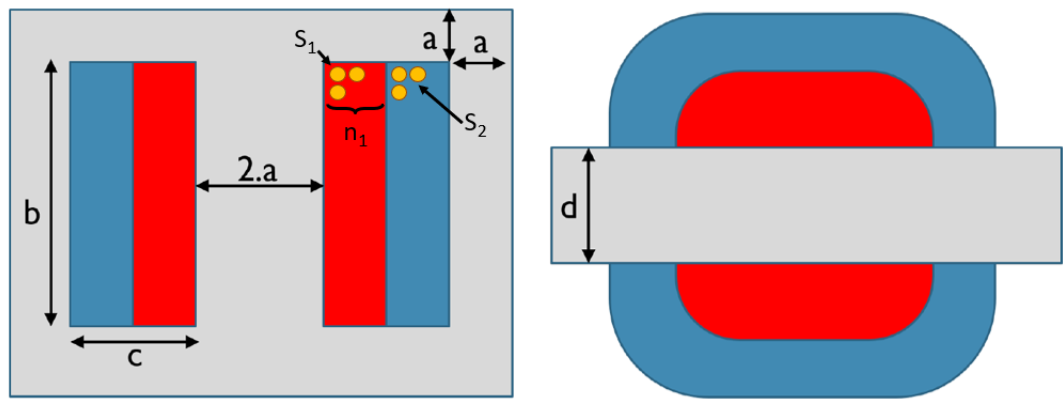

**Objectifs (2) :**

1. **Minimiser les pertes** (1-rendement)
2. **Minimiser la masse**

**Contraintes (6) :**

- Temp. cuivre $\leq$ 120°C
- Temp. fer $\leq$ 100°C
- Chute de tension $\leq$ 10%
- Courant d'excitation $\leq$ 10%
- Facteurs de remplissage $\leq$ 0.6
- Convergence du modèle physique.

Quelques articles sont disponibles dans `Bibliography`.

---

## A) Valider le Modèle Physique

- Aller dans le fichier `MainScripts/A_LaunchModel.m`.

**Objectif :** Exécuter le modèle physique du transformateur (`ConceptionModel.m`) avec un design de test et affiche les résultats.

**Que faire ?**

1. Identifier les variables de conception, les paramètres et les sorties.
2. Résoudre le système non linéaire dans `Model/ConceptionModel.m` en implémentant une méthode de Newton appropriée.
3. Ajouter une recherche de pas (linesearch) dans `Model/ConceptionModelLineSearch.m`.

**Qu'observe-t-on ?**

- Taux de convergence pour différentes entrées de référence `xTest_0`, `xTest_1`, ..., `xTest_4`.
- Le vecteur de sortie est : `[M_tot; Tcuivre; Tfer; DV2/V2; I10/I1; ren; f1; f2; Pj; Pfer ; crit]`.

---

## B) Optimisation à Objectif Unique

- Aller dans le fichier `MainScripts/B_LaunchOptimisation.m`.

**Objectif :** Optimiser selon un UNIQUE objectif (soit les pertes, soit la masse) avec `fmincon` de MATLAB. Cela permet d'obtenir les points extrémaux du front de Pareto.

**Que faire ?**

1. Définir la fonction objectif `myfun` soit comme les pertes, soit comme la masse.
2. Définir la fonction de contrainte `mycon`.
3. Exécuter l'optimisation, pour optimiser la masse, puis les pertes.
4. Expérimenter en changeant le point initial et les paramètres de l'algorithme.

**Qu'observe-t-on ?**

- Noter les valeurs minimales et maximales de la masse et des pertes.
- Le résultat optimisé est-il toujours le même ?

---

## C) Optimisation à Objectif Unique avec Multiple Démarrages

- Aller dans le fichier `MainScripts/C_LaunchOptimisationMultiStart.m`.

**Objectif :** Optimisation mono-objectif à partir de différents points de départ aléatoires, en conservant le meilleur résultat convergé. Cela atténue le risque de rester coincé dans un minimum local.

**Que faire ?**

1. Configurer et exécuter la boucle multistart.
2. Si la Parallel Computing Toolbox est disponible, paralléliser le code en utilisant `parfor`.
3. Expérimenter en changeant les paramètres de l'algorithme, en particulier la tolérance des contraintes.
4. Analyser les résultats.

**Qu'observe-t-on ?**

- Proportion des résultats d'optimisation "bons" vs "mauvais" par rapport aux paramètres de l'algorithme.
- Déterminer un bon nombre de points de départ : on veut un bon résultat final, sans trop compromettre les performances.

---

## D) Scalarisation pondérée (linéaire)

- Aller dans le fichier `MainScripts/D_LaunchOptimisationPonderation.m`.

**Objectif :** Tracer le front de Pareto en optimisant une combinaison linéaire des deux objectifs. En faisant varier le paramètre de pondération `omega` de 0 à 1, on obtient différents points du front de Pareto.

**Que faire ?**

1. Déterminer la fonction objectif et les contraintes.
2. Exécuter l'algorithme et tracer le front de Pareto. Expérimenter avec les paramètres de l'algorithme.
3. La scalarisation linéaire fonctionne-t-elle pour un front de Pareto non convexe ? Pourquoi ?
4. Proposer et implémenter des stratégies pour minimiser le temps de calcul.

**Qu'observe-t-on ?**

- Commenter les fronts de Pareto obtenus avec et sans normalisation.

---

## E) Méthode Epsilon-contrainte

- Aller dans le fichier `MainScripts/E_LaunchOptimisationEpsConstr.m`.

**Objectif :** Trace le front de Pareto en minimisant les pertes sous contrainte de masse ou de pertes, que l'on fait varier.

**Que faire ?**

1. Déterminer la fonction objectif et les contraintes.
2. Exécuter l'algorithme et tracer le front de Pareto. Expérimenter en changeant les paramètres de l'algorithme.
3. La méthode epsilon-contrainte fonctionne-t-elle pour un front de Pareto non convexe ? Pourquoi ?
4. Proposer et implémenter des stratégies pour minimiser le temps de calcul.

**Qu'observe-t-on ?**

- Commenter les fronts de Pareto obtenus avec différentes bornes de contraintes.

---

## F) Algorithme Évolutionniste NSGA-II

- Aller dans le fichier `MainScripts/F_LaunchNSGAII.m`.

**Objectif :** Tracer le front de Pareto avec l'algorithme NSGA-II (Non-dominated Sorting Genetic Algorithm II) de Kalyanmoy Deb et al. NSGA-II est un algorithme évolutionniste basé sur une population.

**Concepts clés :**

- **Basé sur une population :** Maintient simultanément de nombreuses solutions candidates (vs. méthodes à point unique).
- **Tri non-dominé :** Classe les solutions selon leur degré de domination (front 1 = Pareto-optimal).
- **Distance de brassage (crowding distance) :** Maintient la diversité au sein de chaque front pour répartir uniformément les solutions.
- **Élitisme :** Les meilleures solutions des générations parent et enfant survivent pour la génération suivante.
- **Croisement SBX :** Simule le croisement biologique avec un paramètre de distribution `etaX`.
- **Mutation polynomiale :** Ajoute de petites perturbations aléatoires avec une probabilité `pM`.

```mermaid

flowchart TD
    A("Générer population initiale<br/>Taille N = nmbOfIndivs")
    B["Évaluer la fitness<br/>Fct: ObjContr(x)<br/>Sortie: ObjVals 2xN, ConstrVals 7xN"]
    C["Tri non-dominé<br/>NSGA_Rank<br/>Sortie: Ranking, NmbOfFront"]

    A --> B --> C

    subgraph G["Générer population enfant - NSGA_ChildGen"]
        direction TB
        D["Sélection<br/>NSGA_Tournament<br/>Pars: 250x2 indices parents"]
        E["Croisement<br/>NSGA_SBX<br/>pX, etaX <br/>Croisement binaire simulé"]
        F["Mutation<br/>NSGA_Mutate(XIndivs)<br/>pM, etaM<br/>Mutation polynomiale"]
        D --> E --> F
    end

    C --> D

    H["Évaluer la fitness des enfants<br/>ChildObjVals, ChildConstrVals"]
    I["Combiner populations parent et enfant<br/>Par_ChildGen = [ParGen ChildGen]<br/>Taille population = 2N = 1000"]

    F --> H --> I

    subgraph J["Sélection environnementnelle élitiste"]
        direction TB
        K["NSGA_Rank sur population 2N<br/>Tri non-dominé<br/>Distance de brassage"]
        L["Sélectionner N meilleurs individus<br/>Fronts ascendants, brassage descendant<br/>ParGen = N meilleurs individus"]
        K --> L
    end

    I --> K

    M{"Critère d'arrêt<br/>i >= nmbOfGens ?"}

    L --> M
    M -->|Non - génération suivante| D
    M -->|Oui - terminé| N["Retourner front de Pareto final<br/>ParGen: 7x500<br/>ObjVals: 2x500<br/>NmbOfFront: 500x1"]

    style G stroke:#e000ff,stroke-width:2px
    style J stroke:#e000ff,stroke-width:2px
    style K fill:#e8f0ff,stroke:#2455cc,stroke-width:2px
    style N fill:#e8f5e9,stroke:#2e7d32,stroke-width:2px
    style A fill:#e8f0fe,stroke:#4285f4,stroke-width:2px
    style E fill:#fef7e0,stroke:#f9ab00,stroke-width:2px
    style F fill:#fce8e6,stroke:#ea4335,stroke-width:2px
```

**Paramètres à expérimenter :**

| Paramètre             | Defaut | Effet de l'augmentation                           |
| ---------------------- | ------ | ------------------------------------------------- |
|                        |        |                                                   |
| `mbOfIndivs`         | 500    | Plus de diversité, plus lent                     |
|                        |        |                                                   |
| `mbOfGens`           | 100    | Plus de convergence, plus lent                    |
| `etaX` (croisement)  | 0.5    | Enfants plus proches des parents (exploitation)   |
| `etaM` (mutation)    | 0.5    | Mutations plus proches des parents (exploitation) |
| `pM` (taux mutation) | 0.1    | Plus d'exploration, perturbation potentielle      |

**Que faire ?**

1. Expliquer les étapes de l'algorithme NSGA-II.
2. À partir des ressources de `Bibliography`, donner et expliquer 3 indicateurs différents de qualité d'un front de Pareto numérique.
3. Expérimenter en changeant les paramètres.
4. Comparer avec la fonction intégrée `gamultiobj` de MATLAB.

**Qu'observe-t-on ?**

- Qualité du front de Pareto selon certains indicateurs.
- Temps de calcul.

---

## G) Comparaison Complétive des Méthodes

- Aller dans le fichier `MainScripts/G_Comparison.m`.

**Objectif :** A vous de jouer pour comparer les différentes méthodes et implémenter la plus efficace!

**Que faire ?**

1. Comparer différents algorithmes d'optimisation multi-objectif (recherche aléatoire, scalarisation linéaire, epsilon-constraint, algorithme génétique, ...).
2. Essayer d'implémenter la meilleure méthode en termes de qualité du front de Pareto et temps de calcul.
3. Sauvegarder les résultats et tracer la comparaison.

**Qu'observe-t-on ?**

- Qualité du front de Pareto.
- Temps de calcul.